# Fixing the correlation and fitting a new model
### Replication of Sulyok & Walker (2020), *Community movement and COVID-19*

Covers two parts of the project: **(A)** the correlation analysis and **(B)** the model (EDA lives in `analysis/02_eda/`).

**Data:** the team's cleaned panel `data/processed/2026-10-24-panel-clean.csv` (Google CMR + JHU CSSE cases, 134 countries).
The one exception is step A1, which uses the authors' own 2020 snapshots in `data/raw/sulyok-repo/`. JHU revised its case
counts after 2020, so only those snapshots can reproduce the paper's Table S1 number for number.

**Framing:** all results are associations (co-movement and timing), not causal effects; see the team plan in `docs/contributions.md`.

**How to run:** open this notebook in VS Code (Python kernel with `pandas numpy statsmodels linearmodels matplotlib`)
and *Run All*. It takes about 15 minutes, mostly the significance tests in A2.
Each step runs one of the scripts `10_` to `14_`, which can also be run on their own from the repo root.

In [1]:
import os, pathlib
from IPython.display import Image, display
import pandas as pd
pd.set_option("display.width", 160)
# work from the repo root, wherever the notebook was opened from
here = pathlib.Path.cwd()
root = next(p for p in [here, *here.parents] if (p / "data/processed/2026-10-24-panel-clean.csv").exists())
os.chdir(root)
FIG = "outputs/03_reanalysis/figures/"
print("repo root:", root)

## A1. The paper's correlation, replicated exactly, and what's wrong with it
**Paper's method:** for each country and category, Kendall's τ between *raw daily* mobility and *raw daily* cases shifted by
−28…+28 days; keep the shift with the largest |τ|.

**Two stress tests:**
1. **Placebo:** pair each country's mobility with a *randomly chosen other country's* cases. A method that measures a
   country's own mobility–case link should find much weaker correlations for these fake pairs.
2. **Edge lags:** if there is a genuine peak, the "best" lag should rarely sit at the very edge of the search window.

In [2]:
%run analysis/03_reanalysis/10_corr_replicate.py

Paper inputs: 125 countries, 2020-02-15 -> 2020-06-19


Replication vs paper S1 (122 countries matched):
  retail   corr(tau ours, tau paper) = 1.000 | identical best lag in 100% of countries
  grocery  corr(tau ours, tau paper) = 1.000 | identical best lag in 100% of countries
  parks    corr(tau ours, tau paper) = 1.000 | identical best lag in 100% of countries
  transit  corr(tau ours, tau paper) = 1.000 | identical best lag in 100% of countries
  work     corr(tau ours, tau paper) = 1.000 | identical best lag in 100% of countries
  resid    corr(tau ours, tau paper) = 1.000 | identical best lag in 100% of countries

Share of countries whose 'best' lag is at the edge (|lag| >= 26): {'retail': '34%', 'grocery': '34%', 'parks': '38%', 'transit': '32%', 'work': '29%', 'resid': '31%'} | expected if lags were uniform: 11%



Median |tau|  real pairs vs placebo (wrong-country) pairs:
  retail   real 0.49   placebo 0.51   | share |tau|>0.4: real 66%, placebo 71%
  transit  real 0.50   placebo 0.51   | share |tau|>0.4: real 66%, placebo 70%
  work     real 0.47   placebo 0.46   | share |tau|>0.4: real 64%, placebo 65%
  resid    real 0.50   placebo 0.50   | share |tau|>0.4: real 69%, placebo 70%


saved fig1_paper_correlation_problems.png


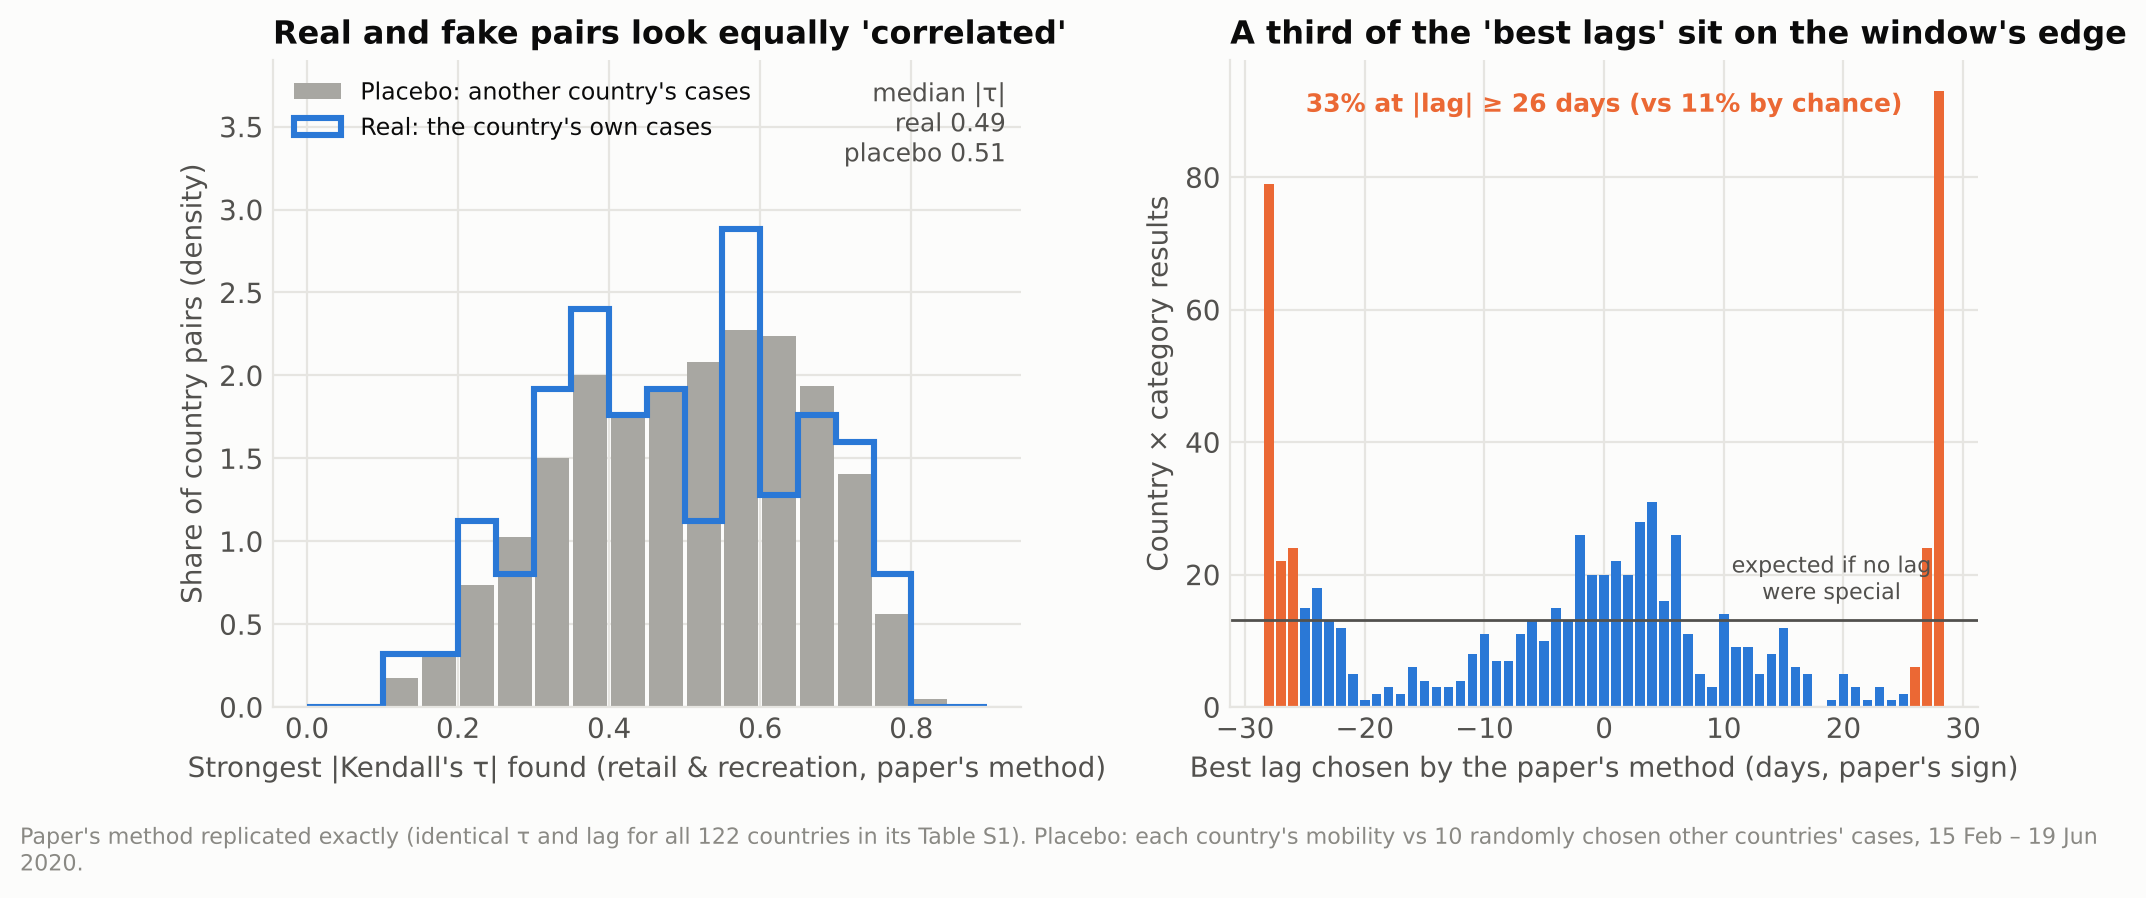

In [3]:
%run analysis/03_reanalysis/14_figures.py 1
display(Image("outputs/03_reanalysis/figures/fig1_paper_correlation_problems.png"))

**Reading it:**
- Our code reproduces the paper's Table S1 exactly: same τ and same best lag for all 122 published countries. So what
  follows is about the *method*, not a coding difference.
- Fake country pairs look as correlated as real ones (median |τ| 0.51 vs 0.49).
- A third of the chosen lags sit at the window edge, where 11% would be expected.

The paper's maps mostly show that **mobility fell everywhere in March while cases rose everywhere**: shared global timing,
not each country's own relationship.

## A2. The fixed correlation
| Step | Paper | Fixed | Why |
|---|---|---|---|
| Smoothing | raw daily | 7-day averages | removes weekday reporting cycles |
| Cases | raw counts | **weekly growth rate** (`growth_7d`) | mobility changes how fast infections *grow*; comparable across country sizes |
| Sample | from 15 Feb | from each country's 100th case | growth from 1→2 cases is noise |
| Shared timing | ignored | **subtract the cross-country average each day** | removes the global trend that fooled the placebo test |
| Mobility | 6 separate categories | **one index** (1st principal component, 92% of variance), categories kept for comparison | the categories are near-duplicates |
| Lag | best of 57 lags, either direction | fixed windows: **transmission** (mobility → growth 7–21 days later), **behaviour** (growth → mobility 0–14 days later) | no lag shopping |
| Significance | none | 499 circular-shift surrogates per country + Benjamini–Hochberg FDR | an honest p-value per country |

**In plain words:** *when a country moved more than the rest of the world that day, did its cases grow faster than the
world's two to three weeks later?*

In [4]:
%run analysis/03_reanalysis/11_corr_fixed.py

[main] 110 countries, through 2020-06-19; PCA share 92.0%; loadings {'retail': 0.46, 'grocery': 0.43, 'transit': 0.45, 'work': 0.45, 'resid': -0.45}


Fixed method, mobility index: peak tau +0.131 at lag +16 (95% CI +0.087 to +0.181); trough -0.048 at lag -20
  placebo |tau| max over lags: 0.010
Paper method, retail: mean tau real -0.021 vs placebo +0.024; corr of profiles 0.62
transmission : median country tau +0.118; right sign 71%; p<0.05 41%; survive FDR q<0.10 40% (44/110)
behaviour    : median country tau -0.011; right sign 52%; p<0.05 18%; survive FDR q<0.10 18% (20/110)
           tau_transmission  tau_behaviour
continent                                 
AF                    0.108          0.081
AS                    0.077         -0.045
EU                    0.164         -0.034
NorthAm               0.037          0.152
OC                    0.019          0.084
SA                    0.187         -0.026


saved fig2_lag_profiles_paper_vs_fixed.png


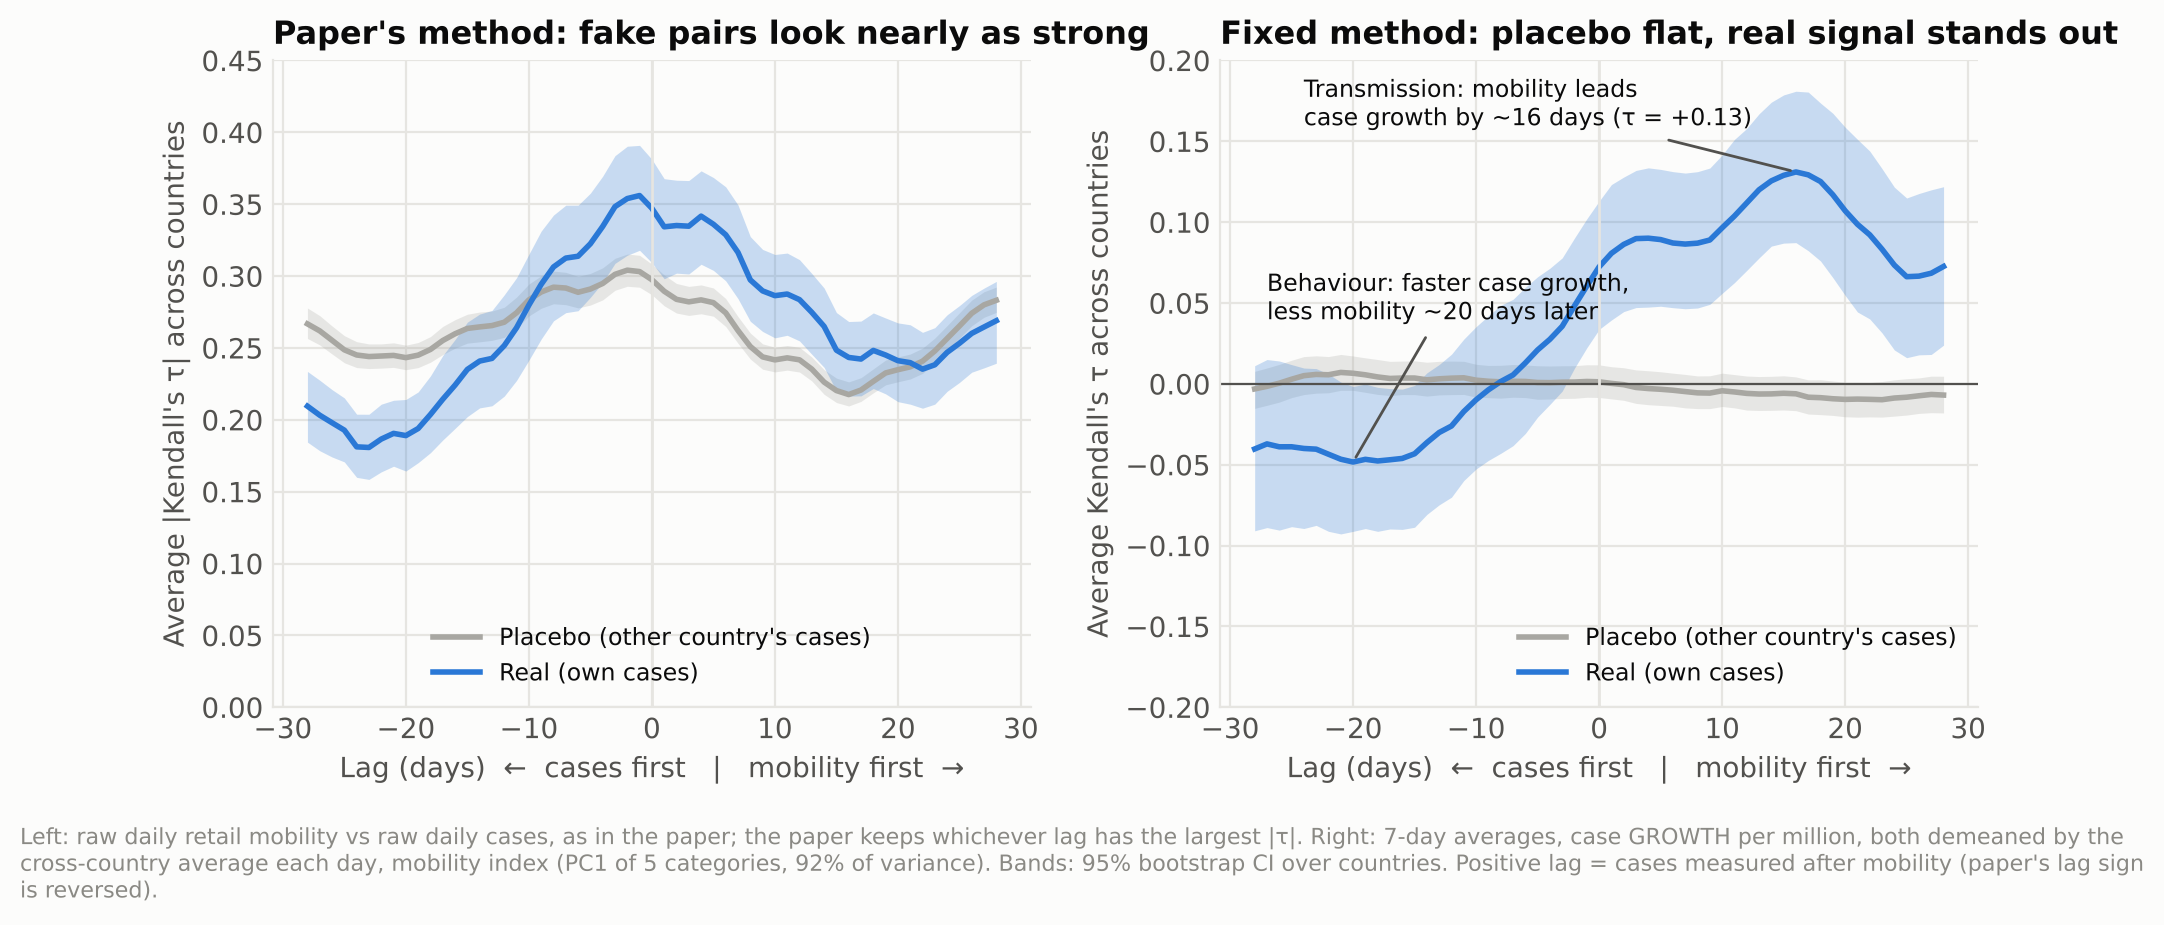

In [5]:
%run analysis/03_reanalysis/14_figures.py 2
display(Image("outputs/03_reanalysis/figures/fig2_lag_profiles_paper_vs_fixed.png"))

**Reading it:**
- After the fix the **placebo profile is flat** (|τ| ≤ 0.01 at every lag), so the shared timing is gone.
- The real profile has a clear **transmission** peak: mobility leads case growth by about **16 days**
  (τ = +0.13, 95% CI 0.09–0.18).
- The reverse direction (case growth followed by lower mobility) is weak on this data, τ ≈ −0.05.

saved fig3_country_results_by_continent.png


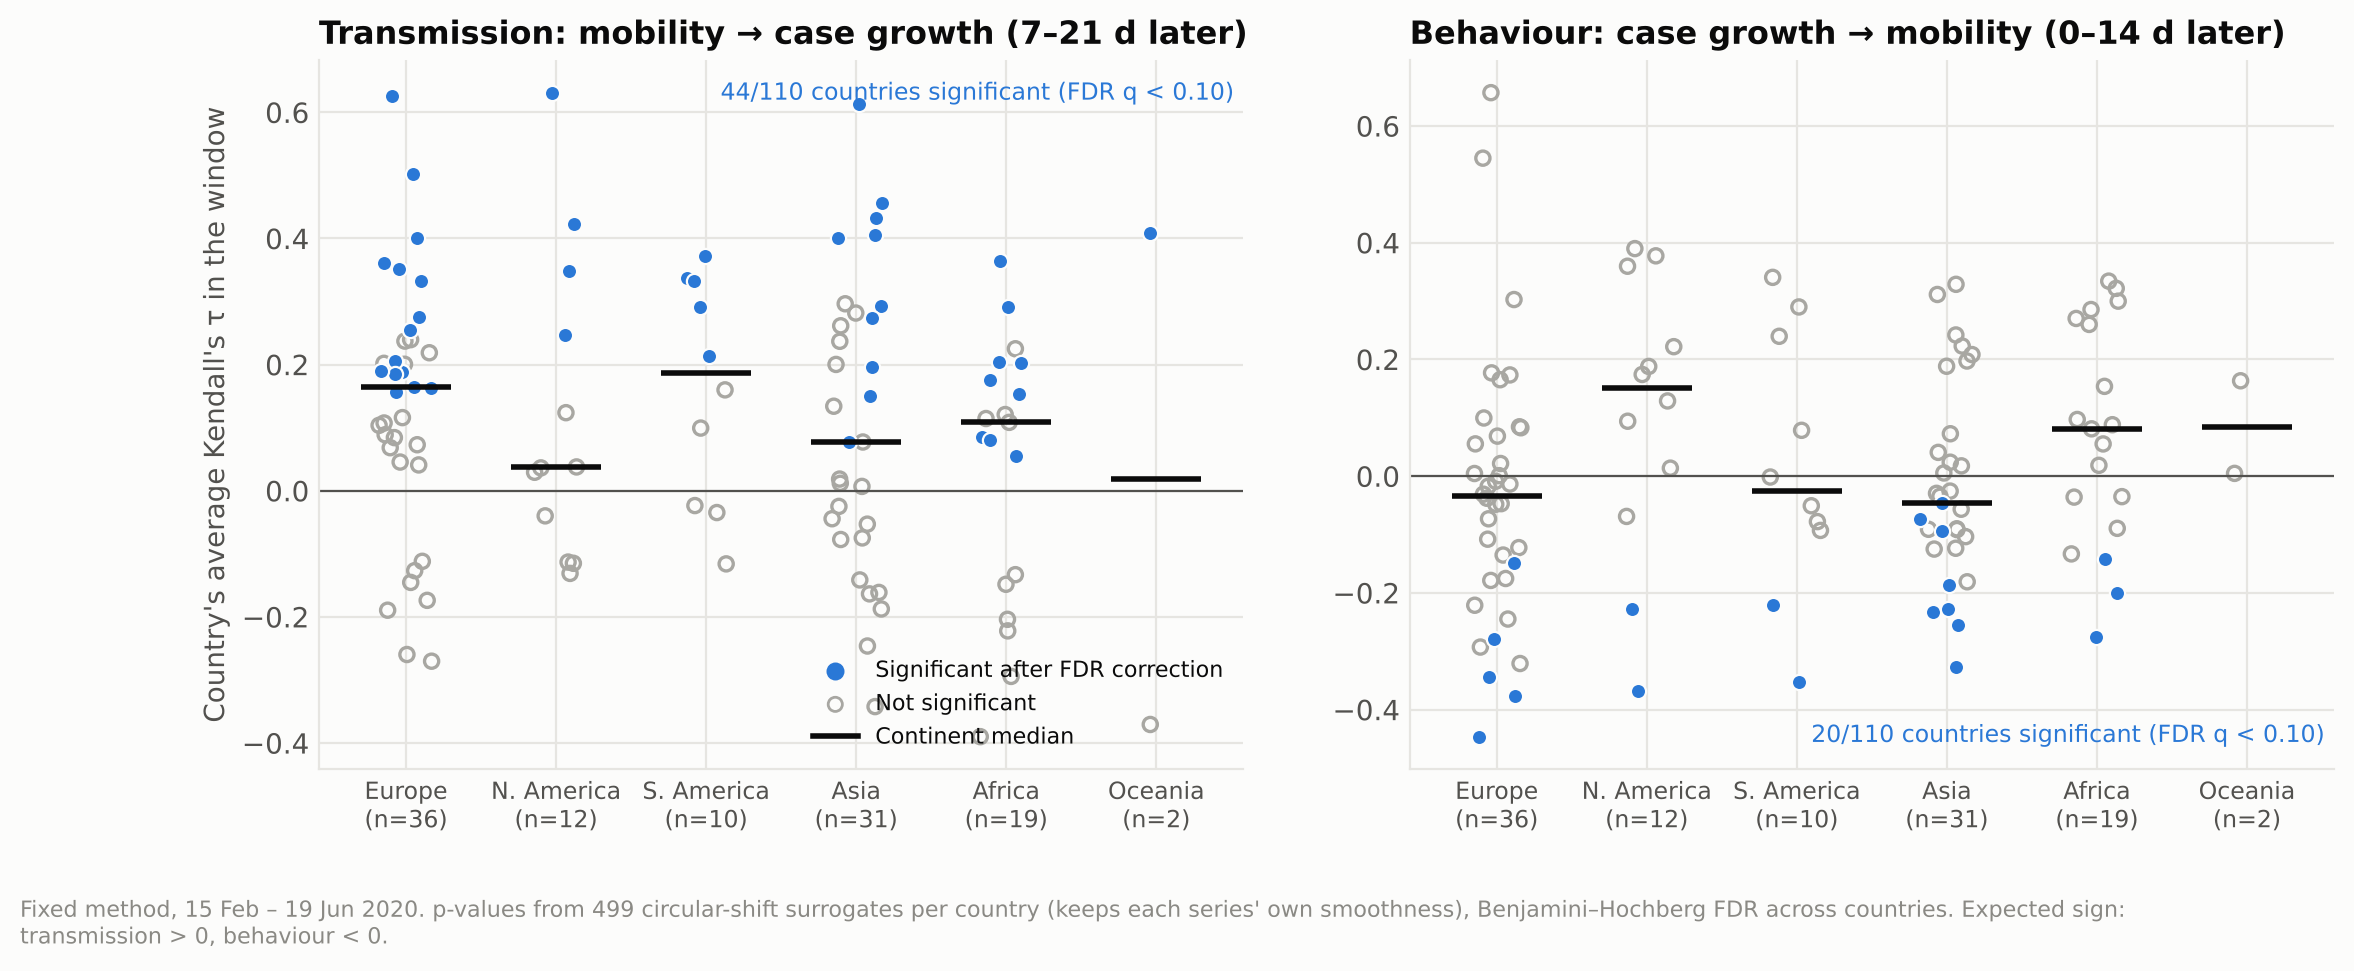

,countries,tau_transmission,significant_transmission,tau_behaviour,significant_behaviour
continent,,,,,
AF,19,0.108,9,0.081,3
AS,31,0.077,10,-0.045,8
EU,36,0.164,15,-0.034,5
NorthAm,12,0.037,4,0.152,2
OC,2,0.019,1,0.084,0
SA,10,0.187,5,-0.026,2


In [6]:
%run analysis/03_reanalysis/14_figures.py 3
display(Image("outputs/03_reanalysis/figures/fig3_country_results_by_continent.png"))
cc = pd.read_csv("outputs/03_reanalysis/corr_country_main.csv", keep_default_na=False, na_values=[""])
cc.groupby("continent").agg(countries=("country","size"), tau_transmission=("tau_transmission","median"),
    significant_transmission=("q_transmission", lambda q: int((q<.10).sum())), tau_behaviour=("tau_behaviour","median"),
    significant_behaviour=("q_behaviour", lambda q: int((q<.10).sum()))).round(3)

**Reading it:**
- The transmission link points the right way in **71%** of countries and survives the false-discovery correction in
  **44 of 110**. Individual country series are short, so many tests are underpowered; the pooled model in B1 adds the power.
- **South America is no longer the exception.** The paper reports positive correlations there. With shared timing removed,
  it has the strongest transmission link of any continent (median τ +0.19). Its epidemic simply started later.
- The behaviour channel is inconsistent across countries (20 of 110 significant, median ≈ 0).

### A3. Robustness: the same analysis through 8 September 2020

In [7]:
%run analysis/03_reanalysis/11_corr_fixed.py --full

[full] 124 countries, through 2020-09-08; PCA share 92.0%; loadings {'retail': 0.46, 'grocery': 0.43, 'transit': 0.45, 'work': 0.45, 'resid': -0.45}


Fixed method, mobility index: peak tau +0.146 at lag +17 (95% CI +0.108 to +0.187); trough -0.101 at lag -28
  placebo |tau| max over lags: 0.007
Paper method, retail: mean tau real +0.073 vs placebo +0.133; corr of profiles 0.82
transmission : median country tau +0.131; right sign 74%; p<0.05 33%; survive FDR q<0.10 27% (33/124)
behaviour    : median country tau -0.000; right sign 50%; p<0.05 10%; survive FDR q<0.10 6% (8/124)
           tau_transmission  tau_behaviour
continent                                 
AF                    0.049          0.018
AS                    0.115         -0.024
EU                    0.176          0.035
NorthAm               0.212          0.047
OC                    0.131         -0.007
SA                    0.216         -0.050


Same transmission peak (τ = +0.15 at 17 days, 33 of 124 countries significant). The behaviour channel fades further
over the summer.

## B1. The new model: panel local projections
One regression per horizon *h* = 0…28 days:

$$\text{growth}_{i,t+h} = \beta_h\,\text{mobility}_{i,t} + \text{(growth and mobility 1–2 weeks earlier)} + \text{country}_i + \text{day}_t + \varepsilon$$

- **Country effects** absorb each country's typical growth (testing, climate, demography).
- **Day effects** absorb anything that hit every country on the same day: the same fix as in A2, inside a regression.
- **History controls** make β measure *new* information in today's mobility. The first days then act as a built-in
  placebo, because mobility today cannot show up in reported cases within a few days.
- SEs are clustered by country. The mirror regression (case growth → future mobility) measures the behaviour channel.

This replaces the paper's GAMM, keeping its distributed-lag idea as a transparent sequence of estimates. It runs on three
samples: the paper's window, through Sep 2020, and the **Sep 2020 – Apr 2022 extension**.

In [8]:
%run analysis/03_reanalysis/12_model_lp.py
%run analysis/03_reanalysis/12_model_lp.py --full
%run analysis/03_reanalysis/12_model_lp.py --ext

[main] countries 119, obs at peak 6629
Transmission: peak beta 0.257 (SE 0.058) at h=17 days; 95% CI excludes 0 at h=[10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 28]
  -> 1 SD more mobility: weekly case growth +29.3% faster ~17 days later
Behaviour: most negative theta -0.064 (SE 0.020) at h=15; CI below 0 at h=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
  -> cases doubling in a week (growth = ln2) lowers mobility by -0.04 SD after 15 days
  retail  : largest beta +0.282 at h=18 (CI +0.187 to +0.377)
  grocery : largest beta +0.081 at h=15 (CI -0.011 to +0.174)
  transit : largest beta +0.244 at h=17 (CI +0.118 to +0.371)
  work    : largest beta +0.149 at h=20 (CI +0.057 to +0.240)
  resid   : largest beta -0.212 at h=17 (CI -0.300 to -0.123)


[full] countries 127, obs at peak 16623
Transmission: peak beta 0.230 (SE 0.052) at h=16 days; 95% CI excludes 0 at h=[11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]
  -> 1 SD more mobility: weekly case growth +25.9% faster ~16 days later
Behaviour: most negative theta -0.077 (SE 0.015) at h=26; CI below 0 at h=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]
  -> cases doubling in a week (growth = ln2) lowers mobility by -0.05 SD after 26 days
  retail  : largest beta +0.342 at h=16 (CI +0.262 to +0.421)
  grocery : largest beta -0.189 at h=7 (CI -0.271 to -0.106)
  transit : largest beta +0.219 at h=15 (CI +0.134 to +0.303)
  work    : largest beta -0.081 at h=8 (CI -0.145 to -0.017)
  resid   : largest beta -0.248 at h=17 (CI -0.332 to -0.163)


[ext] countries 131, obs at peak 71495
Transmission: peak beta 0.133 (SE 0.023) at h=28 days; 95% CI excludes 0 at h=[14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]
  -> 1 SD more mobility: weekly case growth +14.2% faster ~28 days later
Behaviour: most negative theta -0.102 (SE 0.016) at h=24; CI below 0 at h=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]
  -> cases doubling in a week (growth = ln2) lowers mobility by -0.07 SD after 24 days
  retail  : largest beta +0.115 at h=28 (CI +0.071 to +0.159)
  grocery : largest beta -0.215 at h=7 (CI -0.265 to -0.165)
  transit : largest beta +0.122 at h=28 (CI +0.079 to +0.165)
  work    : largest beta -0.089 at h=7 (CI -0.119 to -0.059)
  resid   : largest beta -0.131 at h=28 (CI -0.160 to -0.101)


saved fig4_local_projections.png


saved fig5_categories.png


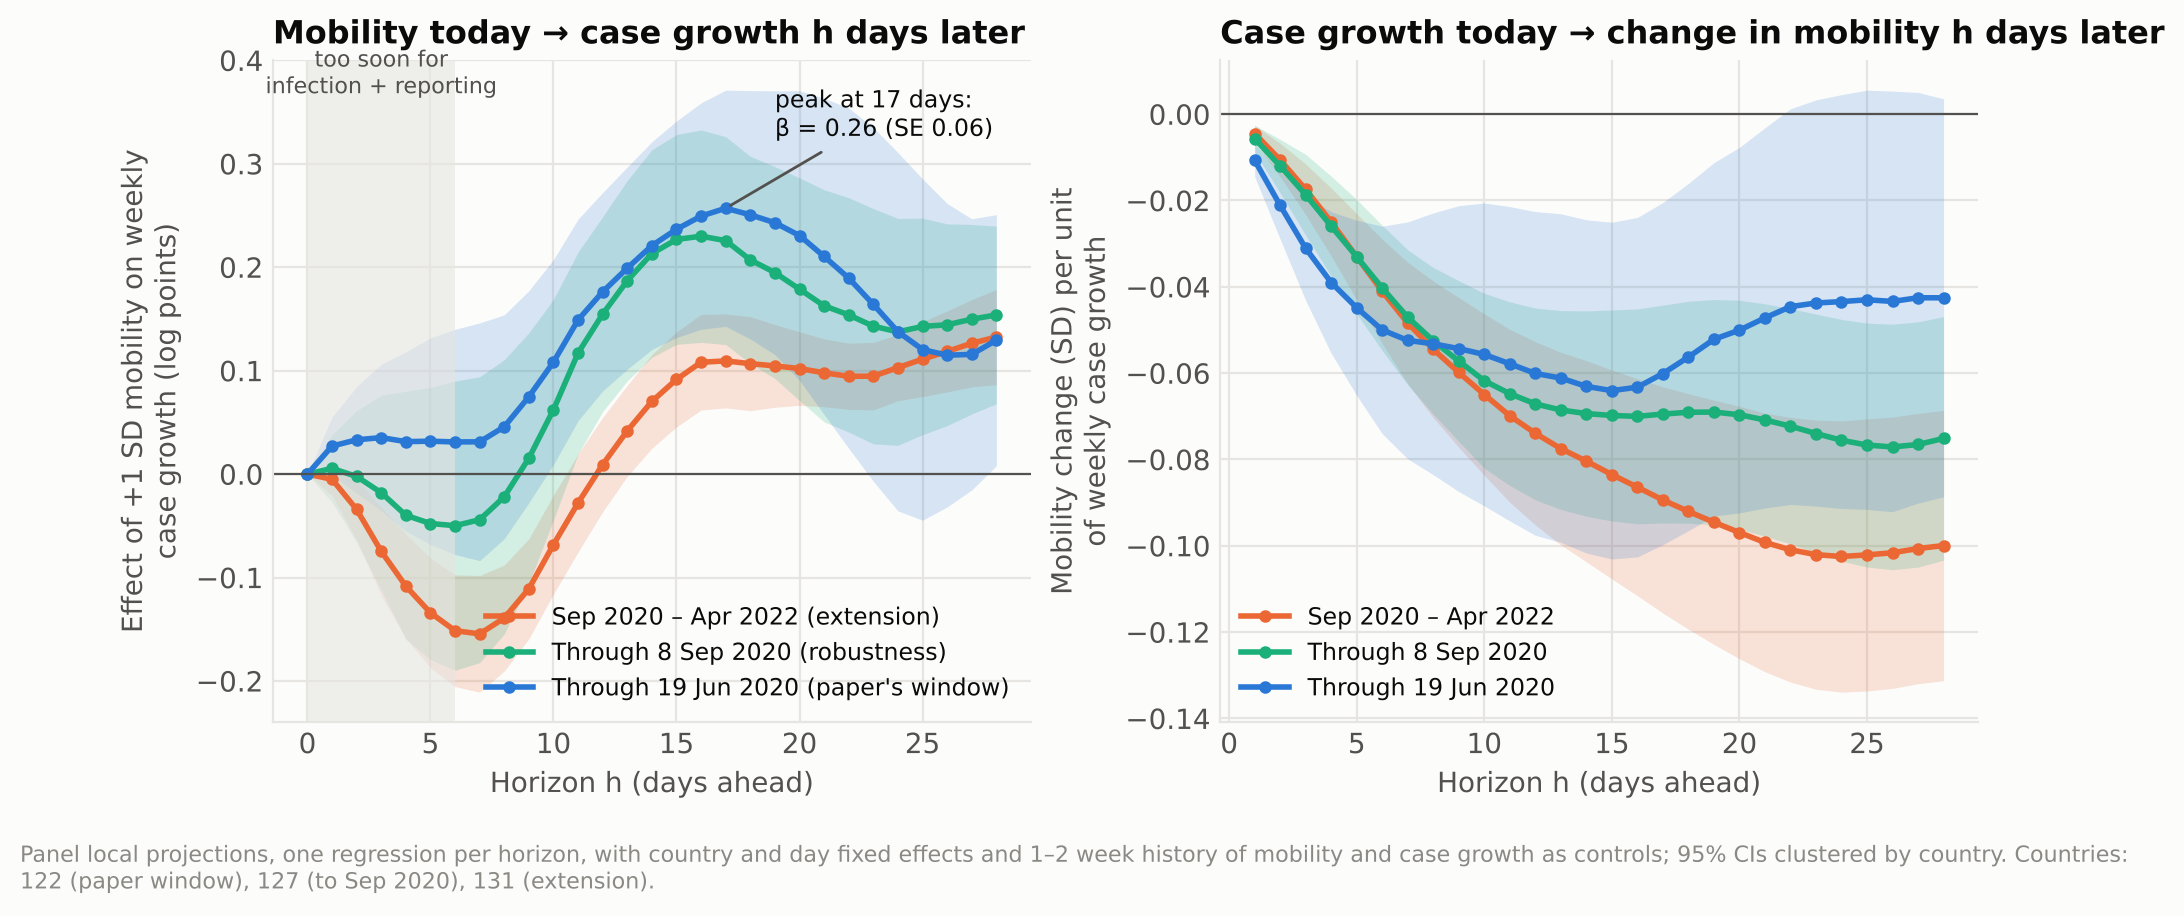

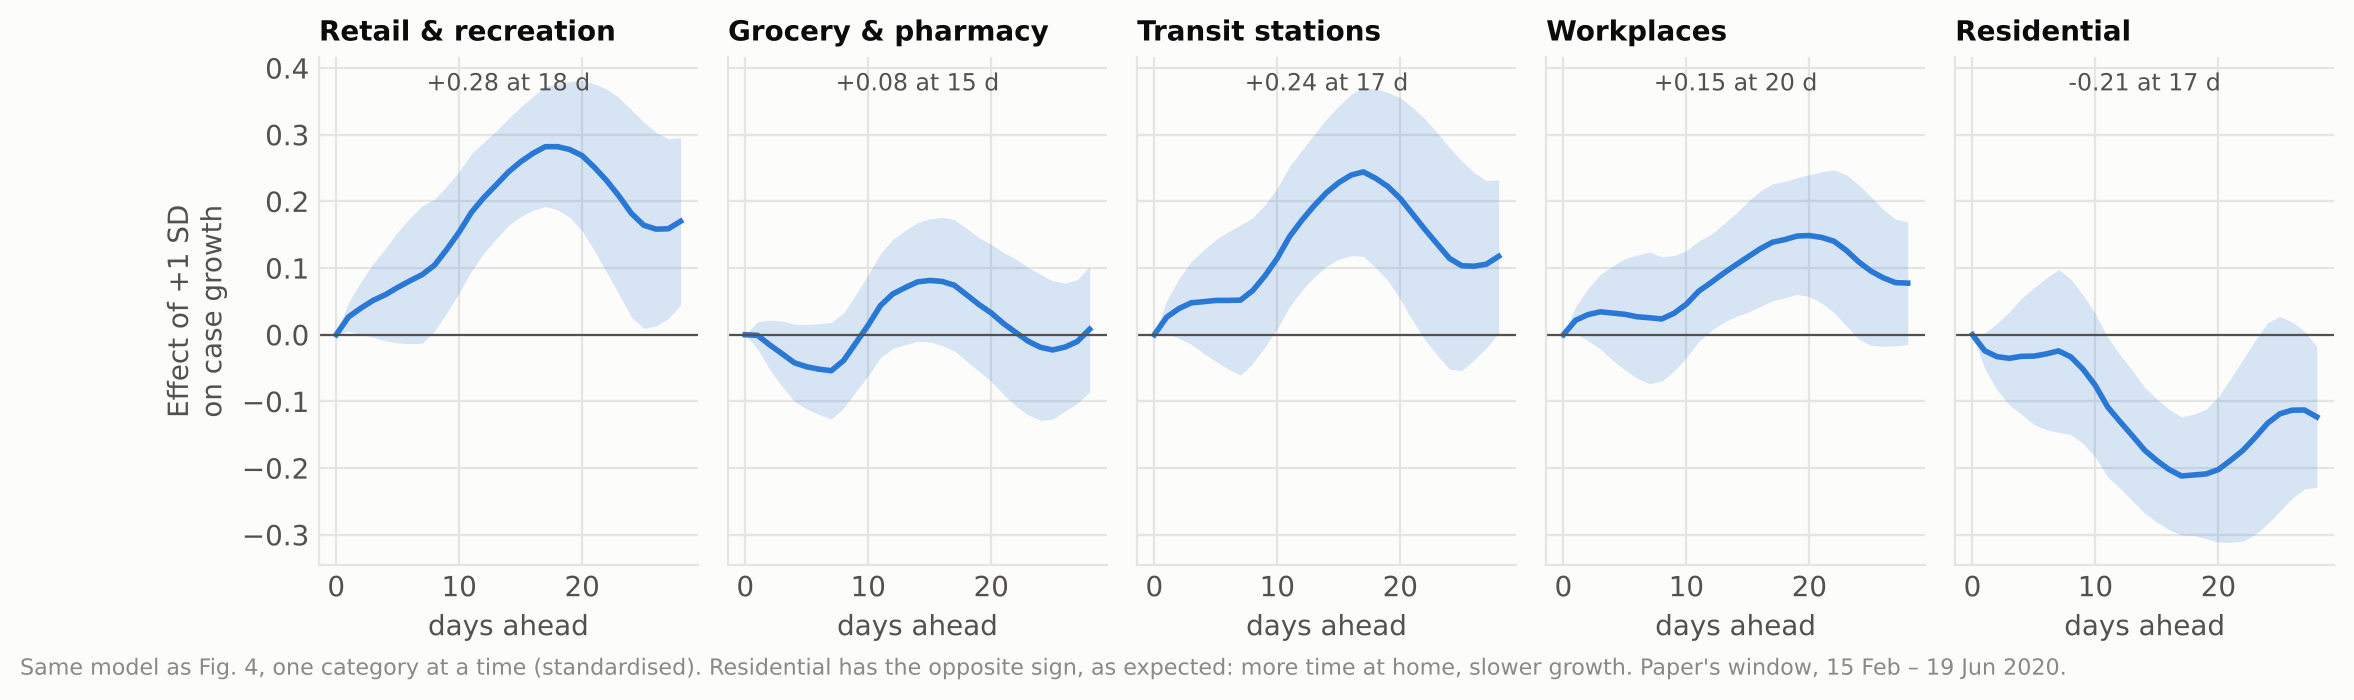

In [9]:
%run analysis/03_reanalysis/14_figures.py 4 5
display(Image("outputs/03_reanalysis/figures/fig4_local_projections.png"))
display(Image("outputs/03_reanalysis/figures/fig5_categories.png"))

**Reading it:**
- **Shape:** the effect is not distinguishable from zero for the first 9 days, as biology requires. It becomes significant
  from day 10 and **peaks at 17 days: β = 0.26 (SE 0.06)**.
- **Scale:** 1 SD of the index ≈ 26 percentage points of retail mobility versus the pre-COVID baseline, and a typical first
  lockdown moved countries ≈ 2.4 SD.
- **Through Sep 2020:** the same shape (peak 0.23 at 16 days, significant from day 11).
- **Sep 2020 – Apr 2022:** the link is about **half as strong (0.13) and arrives later**, consistent with masks, distancing
  and vaccines weakening the mobility–transmission link after the first wave.
- **Categories:** retail (+0.28) and transit (+0.24) are strongest, residential has the opposite sign as expected, and
  grocery is not significant. In the paper only retail was significant, because five near-duplicate categories were
  entered together.

## B2. Does mobility help *forecast*? An honest test
The paper's validation has four problems:
- it predicts 20 Jun–8 Sep using the **actual** mobility of those days, which nobody knows in advance;
- it extrapolates a date trend 80 days ahead;
- it scores pooled raw counts, so the US, Brazil and India dominate;
- it runs Diebold–Mariano on countries stacked into one series.

**Here instead:**
- **Real-time forecasts** of log cases 7, 14 and 21 days ahead, using only information available on the forecast date,
  re-estimated weekly.
- **Nested models:** **M0** naive (no change), **M1** case momentum, **M2** momentum + mobility.
- **Three mobility versions** (levels, week-on-week changes, relative to other countries). The version is **chosen on a
  May–June validation window before looking at the test period**.
- **Fair scoring:** every country counts equally, and Diebold–Mariano runs on the daily cross-country average loss
  difference with HAC errors.

In [10]:
%run analysis/03_reanalysis/13_model_forecast.py

Validation (origins 2020-05-01 -> 2020-06-05), mean abs log error:
M0 naive                 0.5232
M1 momentum              0.5231
M2a mobility level       0.5178
M2b mobility change      0.5139
M2c relative mobility    0.5224
-> chosen mobility model: M2b mobility change



Test: real-time 14-day forecasts, 128 countries, 67 origins, 8223 forecasts
  M0 naive                 mean abs error 0.474 (~61% off)
  M1 momentum              mean abs error 0.466 (~59% off)
  M2a mobility level       mean abs error 0.469 (~60% off)
  M2b mobility change      mean abs error 0.464 (~59% off)   <- chosen on validation
  M2c relative mobility    mean abs error 0.464 (~59% off)
                model          vs  loss_reduction      t     p  share_countries_better
          M1 momentum    M0 naive           0.013  5.513 0.000                   0.555
   M2a mobility level    M0 naive           0.011  2.803 0.005                   0.508
   M2a mobility level M1 momentum          -0.002 -1.055 0.291                   0.547
  M2b mobility change    M0 naive           0.014  6.195 0.000                   0.539
  M2b mobility change M1 momentum           0.001  1.287 0.198                   0.523
M2c relative mobility    M0 naive           0.015  6.651 0.000                   

 h  M0 naive  M1 momentum  M2a mobility level  M2b mobility change  M2c relative mobility  dm_t_chosen_vs_M1  dm_p
 7     0.323        0.318               0.319                0.317                  0.316              0.269 0.788
14     0.474        0.466               0.469                0.464                  0.464              1.287 0.198
21     0.618        0.607               0.608                0.606                  0.606              0.768 0.443
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0824      0.017      4.819      0.000       0.049       0.116
growth         0.2103      0.065      3.221      0.001       0.082       0.338
growth_l7      0.2222      0.028      7.813      0.000       0.166       0.278
dmob7         -0.1656      0.059     -2.793      0.005      -0.282      -0.049
dmob14         0.1626      0.053      3.066      0.002       0.059

saved fig6_forecasting.png


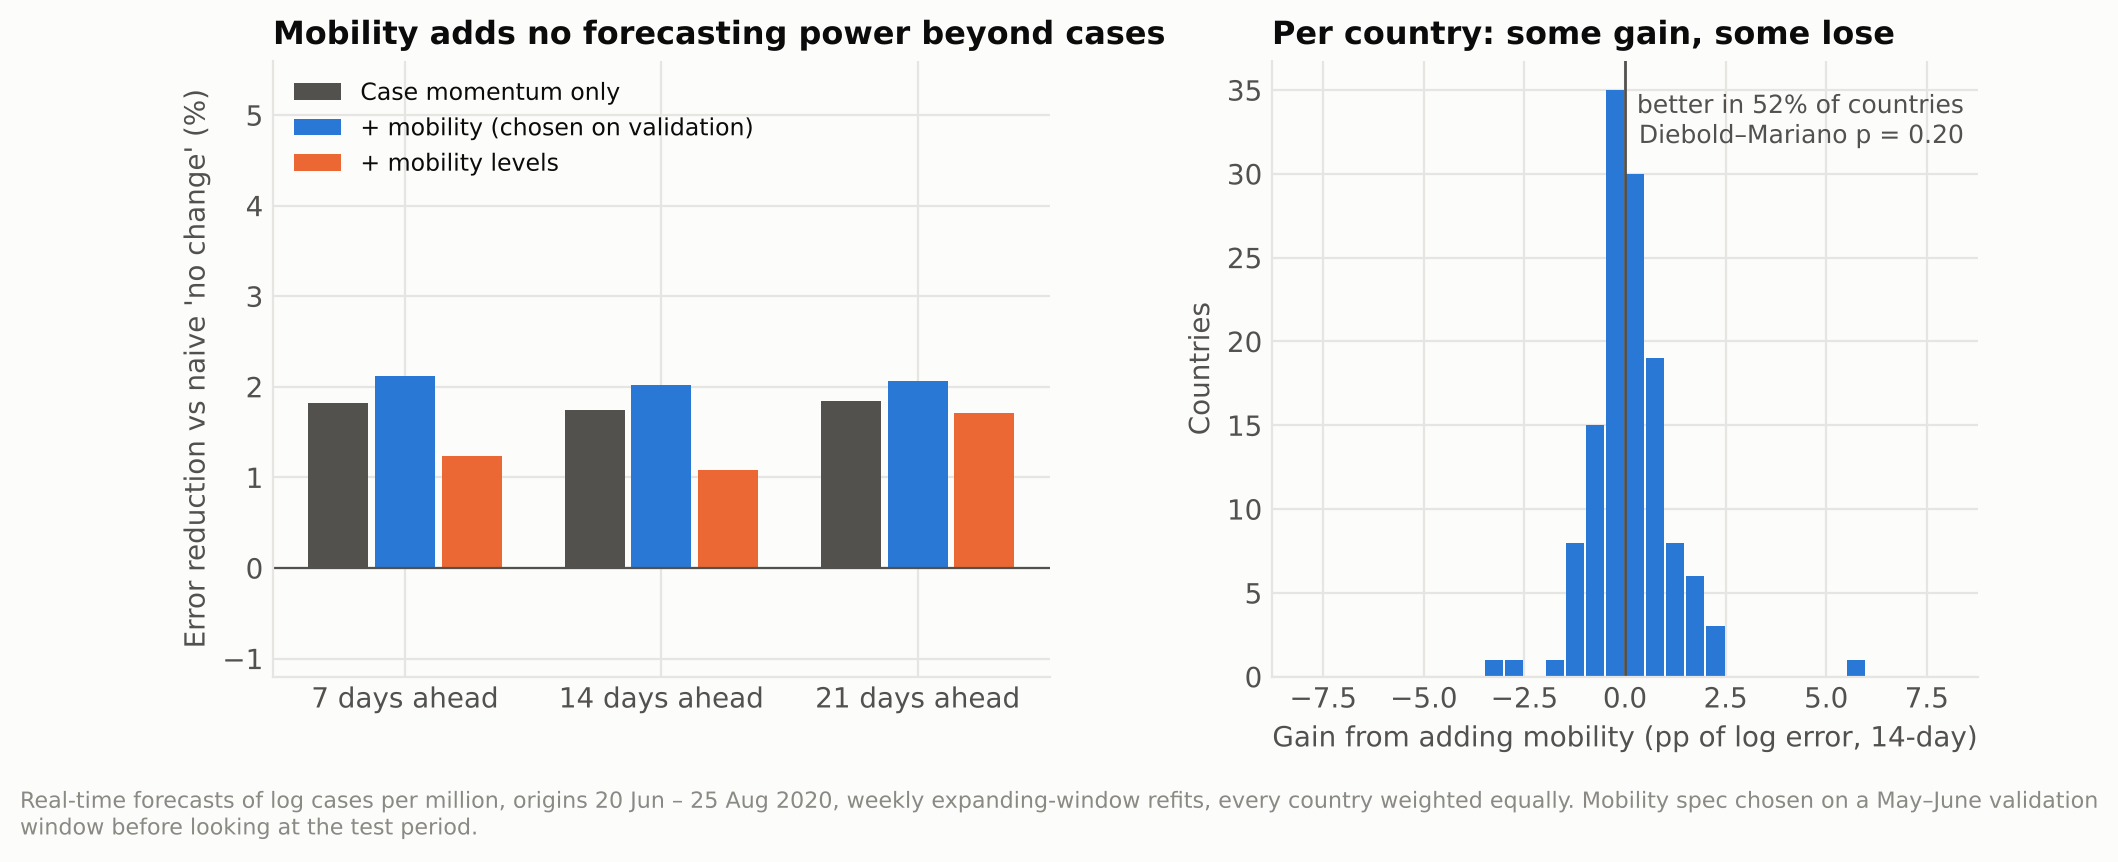

,model,vs,loss_reduction,t,p,share_countries_better
0,M1 momentum,M0 naive,0.013,5.513,0.000,0.555
1,M2a mobility level,M0 naive,0.011,2.803,0.005,0.508
2,M2a mobility level,M1 momentum,-0.002,-1.055,0.291,0.547
3,M2b mobility change,M0 naive,0.014,6.195,0.000,0.539
4,M2b mobility change,M1 momentum,0.001,1.287,0.198,0.523
5,M2c relative mobility,M0 naive,0.015,6.651,0.000,0.555
6,M2c relative mobility,M1 momentum,0.001,1.987,0.047,0.562


In [11]:
%run analysis/03_reanalysis/14_figures.py 6
display(Image("outputs/03_reanalysis/figures/fig6_forecasting.png"))
pd.read_csv("outputs/03_reanalysis/forecast_dm.csv").round(3)

**Reading it:**
- Case momentum beats the naive forecast (p < 0.001).
- **Adding mobility does not significantly improve on momentum** at any horizon. At 14 days the error is 0.464 vs 0.466
  (DM p = 0.20), and mobility does better in only about half of countries.

This is consistent with B1, not a contradiction. Changes in mobility show up in case growth about two weeks later, so by
the time you forecast, that signal is already visible in recent case growth, which the momentum model uses. **Mobility helps describe how
the epidemic evolved, but adds no extra forecasting signal.**

The paper's own three GAMMs are refitted separately in R (mgcv + dlnm), as in the team plan.

## Notes on the authors' shared R code
- The residential lag is overwritten with the workplace lag (`results$residential... <- results$workplaces... - 29`).
  The published S1 table is unaffected.
- Model 2 smooths `workplaces + residential` as **one** summed variable.
- The distributed-lag crossbasis uses lags **0 to 14 days back**, not ±14 as the text says.
- Country names are merged without harmonisation, which drops South Korea, Taiwan, Myanmar, Côte d'Ivoire, Cabo Verde and
  the Bahamas.

## Limitations
- **Observational data.** Day and country effects plus history controls remove a lot, but anything that moves mobility
  *and* later growth within a country (mask rules, testing changes) is not separated out. The brief's same-data-sources
  rule rules out policy indices.
- **Reported cases aren't infections**, and testing changed a lot in 2020.
- **Google users aren't the whole population.**